# Inventory Image Tagging via Handcrafted Features and a Small CNN: Phase 1 (ML evaluation)
Fashion-MNIST (official split). 9 final models: {LogReg, k-NN, RF, RBF-SVM} x {pixels, HOG} + 1 CNN.
**Run top to bottom, no manual steps.** Held-out data is first loaded in section 8 and nowhere earlier.
All numbers below are produced by code in this notebook; nothing is hand-typed.

## 0. Setup and environment

In [ ]:
import os
from pathlib import Path

repo_dir = Path("/content/fashion-tagging")

if (repo_dir / "src" / "config.py").exists():
    os.chdir(repo_dir)
    print("Repository already exists. Using:", os.getcwd())
else:
    print("Repository files not found at:", repo_dir)
    print("Current directory:", os.getcwd())
    print("Contents:", os.listdir("/content"))

Repository already exists. Using: /content/fashion-tagging


In [ ]:
!pwd
!git status --short
!git log -1 --oneline
!ls results

/content/fashion-tagging
 M figures/eda_centroid_heatmap.png
 M figures/eda_class_distribution.png
 M figures/eda_confusable_panel.png
 M figures/eda_mean_images.png
 M figures/eda_pca_scatter.png
 M figures/eda_pca_variance.png
 M figures/eda_samples_per_class.png
 M results/data_quality.json
?? figures/hog_example.png
?? results/environment.json
?? results/tuning_knn_hog.csv
?? results/tuning_knn_pixels.csv
?? results/tuning_logreg_hog.csv
?? results/tuning_logreg_pixels.csv
?? results/tuning_rf_hog.csv
?? results/tuning_rf_pixels.csv
?? results/tuning_svm_pixels.csv
d6c44d2 (HEAD -> main, origin/main, origin/HEAD) Enforce holdout test gate and document HOG selection
data_quality.json    tuning_knn_hog.csv        tuning_rf_hog.csv
environment.json     tuning_knn_pixels.csv     tuning_rf_pixels.csv
hog_sensitivity.csv  tuning_logreg_hog.csv     tuning_svm_pixels.csv
split_audit.json     tuning_logreg_pixels.csv


In [ ]:
%cd /content/fashion-tagging

# Inspect the existing tuning function before running anything.
!grep -n -A100 'def run_classical_tuning' src/experiments.py

/content/fashion-tagging
97:def run_classical_tuning(feats, y_tr, y_val, grids=DEFAULT_GRIDS, results_dir=RESULTS_DIR):
98-    """Tune all 8 (model, representation) pairs on validation; save results/tuning_<model>_<rep>.csv."""
99-    results_dir = Path(results_dir)
100-    results_dir.mkdir(parents=True, exist_ok=True)
101-    best = {}
102-    for rep in REPRESENTATIONS:
103-        for model_name in MODEL_NAMES:
104-            X_tr, X_val = feats[rep]["train"], feats[rep]["val"]
105-            subset_n = SVM_TUNE_N if model_name == "svm" else None  # SVM is tuned on a stratified subset
106-            start = time.perf_counter()
107-            params, tuning_df = tune_classical(model_name, X_tr, y_tr, X_val, y_val,
108-                                               grids[model_name], subset_n=subset_n, seed=SEED)
109-            tuning_df.to_csv(results_dir / f"tuning_{model_name}_{rep}.csv", index=False)
110-            best[(model_name, rep)] = dict(params)
111-            note

In [ ]:
import os, sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not Path("src/config.py").exists():
    repo = os.environ.get("FASHION_REPO_URL", "https://github.com/manas-2212/fashion-tagging.git")  # URL as given in README.md
    subprocess.run(["git", "clone", repo, "fashion-tagging"], check=True)
    os.chdir("fashion-tagging")
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
sys.path.insert(0, str(Path.cwd()))

In [ ]:
import copy, json, time, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
%matplotlib inline

from src.config import (SEED, CLASS_NAMES, NUM_CLASSES, N_TRAIN, N_VAL, PIXEL_DIM, HOG_PARAMS, HOG_DIM,
                        BENCH_BATCH_SIZE, SVM_TUNE_N, ROOT, DATA_DIR, RESULTS_DIR, FIGURES_DIR, set_global_seed)
from src.data import (load_training_dataset, load_test_dataset, verify_training_dataset, verify_test_dataset,
                      prepare_splits, find_duplicates, pca_projection, class_centroid_distances, sanity_baselines)
from src.features import flatten_pixels, extract_hog_features, hog_feature_dim, plot_hog_example, cached_features
from src.classical_models import overfit_check, classical_param_count
from src.evaluation import (evaluate_predictions, top_confusions, plot_confusion_matrix, show_prediction_examples,
                            compare_errors, plot_model_comparison, plot_per_class_recall_heatmap, bootstrap_ci)
from src.experiments import (build_feature_sets, run_classical_tuning, run_classical_final_fits, freeze_selection)
from src.reporting import get_environment_info, RESULT_COLUMNS, build_results_table, save_results_table
from src.cnn import (compute_mean_std, make_cnn_tensor, build_cnn, train_cnn, predict_cnn, plot_learning_curves)
from src.benchmarking import count_trainable_params, benchmark_cnn_inference, benchmark_classical_inference

RESULTS_DIR.mkdir(exist_ok=True); FIGURES_DIR.mkdir(exist_ok=True)
set_global_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
env = get_environment_info()
print(json.dumps(env, indent=2, default=str))
(RESULTS_DIR / "environment.json").write_text(json.dumps(env, indent=2, default=str))
print("training device:", device, "| torch threads:", torch.get_num_threads(), "| os.cpu_count():", os.cpu_count())

{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "cpu": "x86_64 (2 logical cores)",
  "ram": "12.7 GB",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "sklearn": "1.6.1",
  "skimage": "0.25.2",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "cuda_available": true,
  "gpu_name": "Tesla T4",
  "torch_threads": 1,
  "seed": 42
}
training device: cuda | torch threads: 1 | os.cpu_count(): 2


## 1. Load and integrity checks

In [ ]:
# Pre-gate: load and validate ONLY the official training split.
X_train_full, y_train_full = load_training_dataset()
integrity = verify_training_dataset(X_train_full, y_train_full)
print(integrity)
print(X_train_full.shape, X_train_full.dtype, y_train_full.shape, y_train_full.dtype)


{'train_shape': [60000, 28, 28], 'pixel_min': 0, 'pixel_max': 255, 'train_class_counts': [6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000], 'classes_aligned_with_torchvision': True}
(60000, 28, 28) uint8 (60000,) int64


## 2. EDA and data quality (Akhil)
All statistics use the official 60k train images or the 54k train split (same deterministic split as section 3). No held-out image or label is used here.
Held-out class balance (1,000 per class) is asserted inside `verify_dataset` in section 1 and is not plotted.

In [ ]:
import json
import matplotlib.pyplot as plt
import numpy as np
from src.config import CLASS_NAMES, FIGURES_DIR, RESULTS_DIR, SEED
from src.data import class_centroid_distances, pca_projection, prepare_splits, stratified_subset

FIGURES_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
s = prepare_splits(X_train_full, y_train_full)   # same deterministic split as section 3
X_tr, y_tr = s["X_train"], s["y_train"]
rng = np.random.default_rng(SEED)

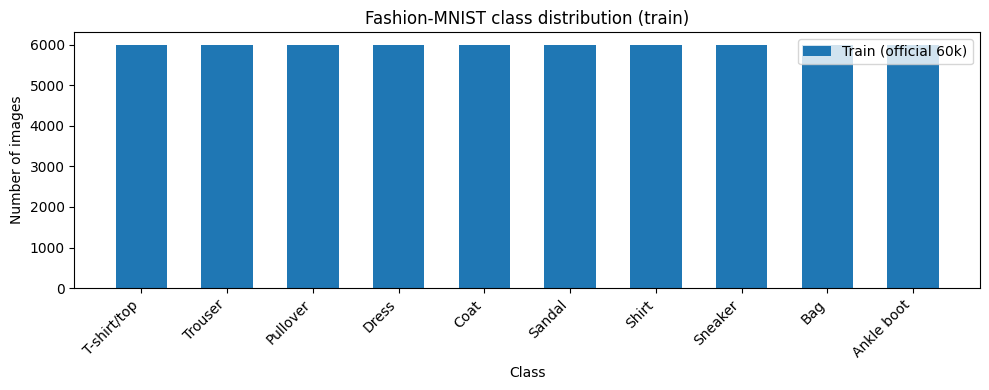

In [ ]:
# a) Class distribution (official 60k train)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(np.arange(10), np.bincount(y_train_full, minlength=10), 0.6, label="Train (official 60k)")
ax.set_xticks(np.arange(10))
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
ax.set_title("Fashion-MNIST class distribution (train)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_class_distribution.png", dpi=150)
plt.show()

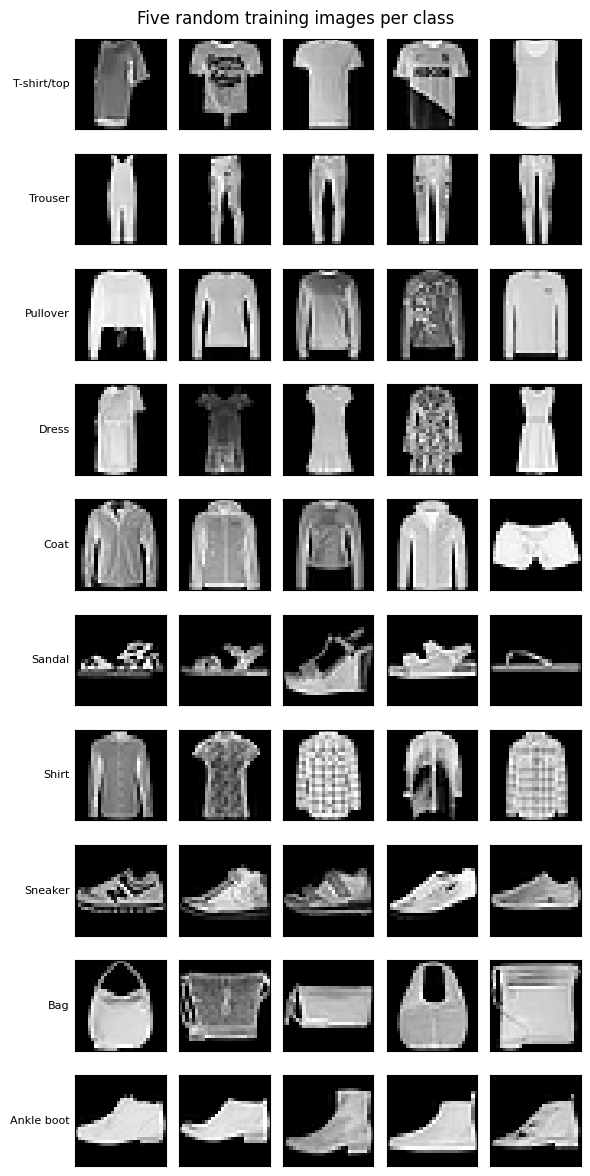

In [ ]:
# b) 5 random images per class (fixed seed, from the train split)
fig, axes = plt.subplots(10, 5, figsize=(6, 12))
for c in range(10):
    idx = rng.choice(np.where(y_tr == c)[0], 5, replace=False)
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(X_tr[i], cmap="gray")
        ax.set_xticks([])
        ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(CLASS_NAMES[c], rotation=0, ha="right", va="center", fontsize=8)
fig.suptitle("Five random training images per class")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_samples_per_class.png", dpi=150)
plt.show()

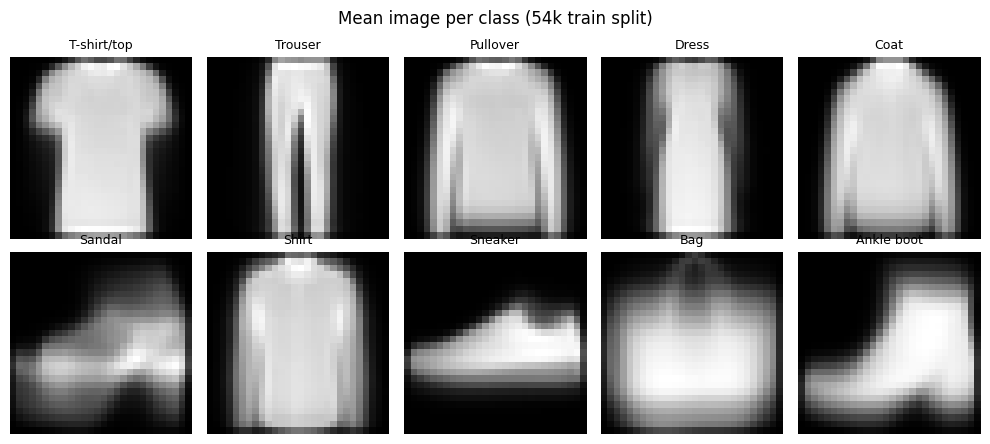

In [ ]:
# c) Mean image per class (train split)
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(X_tr[y_tr == c].mean(axis=0), cmap="gray")
    ax.set_title(CLASS_NAMES[c], fontsize=9)
    ax.axis("off")
fig.suptitle("Mean image per class (54k train split)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_mean_images.png", dpi=150)
plt.show()

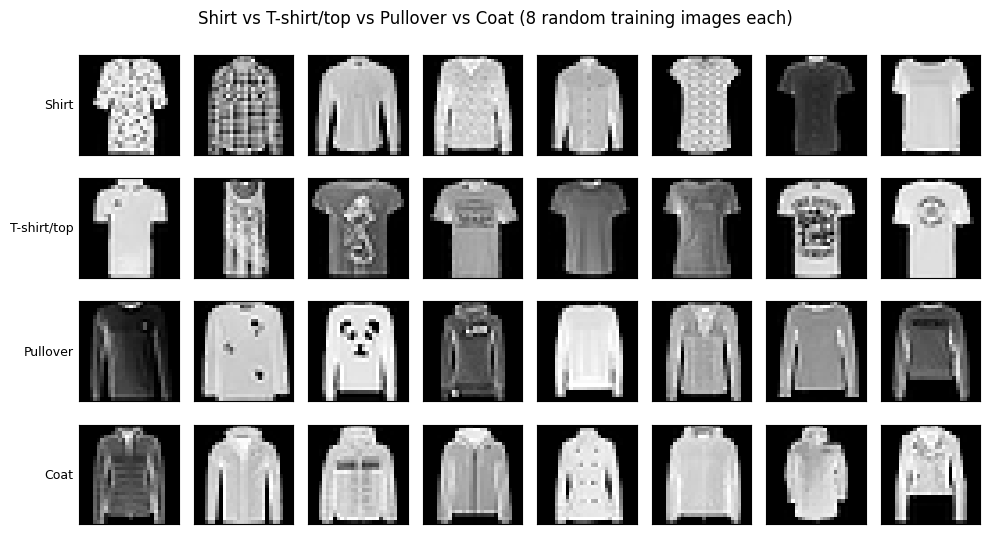

In [ ]:
# d) Confusable upper-body classes: 8 examples each
panel = [6, 0, 2, 4]  # Shirt, T-shirt/top, Pullover, Coat
fig, axes = plt.subplots(4, 8, figsize=(10, 5.5))
for r, c in enumerate(panel):
    idx = rng.choice(np.where(y_tr == c)[0], 8, replace=False)
    for j, i in enumerate(idx):
        ax = axes[r, j]
        ax.imshow(X_tr[i], cmap="gray")
        ax.set_xticks([])
        ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(CLASS_NAMES[c], rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Shirt vs T-shirt/top vs Pullover vs Coat (8 random training images each)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_confusable_panel.png", dpi=150)
plt.show()

In [ ]:
# e) Pixel statistics on the TRAIN split only (scale 0-1)
pix = {
    "n_images": int(len(X_tr)),
    "mean": float(X_tr.mean(dtype=np.float64) / 255),
    "std": float(X_tr.std(dtype=np.float64) / 255),
    "fraction_zero_pixels": float((X_tr == 0).mean()),
    "per_class_mean_intensity": {CLASS_NAMES[c]: float(X_tr[y_tr == c].mean(dtype=np.float64) / 255)
                                 for c in range(10)},
}
print(json.dumps(pix, indent=2))
dq_path = RESULTS_DIR / "data_quality.json"
dq = json.loads(dq_path.read_text()) if dq_path.exists() else {}
dq["pixel_stats_train54k"] = pix

{
  "n_images": 54000,
  "mean": 0.28620900776977454,
  "std": 0.353159743293243,
  "fraction_zero_pixels": 0.5021429988662132,
  "per_class_mean_intensity": {
    "T-shirt/top": 0.3255806961673558,
    "Trouser": 0.22315951287922578,
    "Pullover": 0.37713047719087633,
    "Dress": 0.2584849532405555,
    "Coat": 0.38488897132927247,
    "Sandal": 0.13675431190994916,
    "Shirt": 0.3327026958931721,
    "Sneaker": 0.1678924606879789,
    "Bag": 0.3540443520000593,
    "Ankle boot": 0.30145164639930044
  }
}


PCA variance, PC1 and PC2: [0.28987887501716614, 0.17773300409317017] | first 10: 0.7197431921958923 | 50: 0.8625684976577759


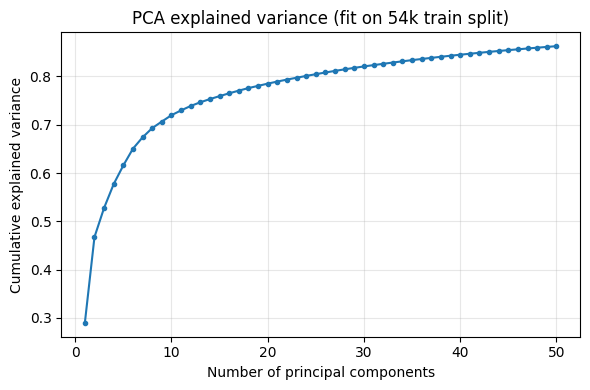

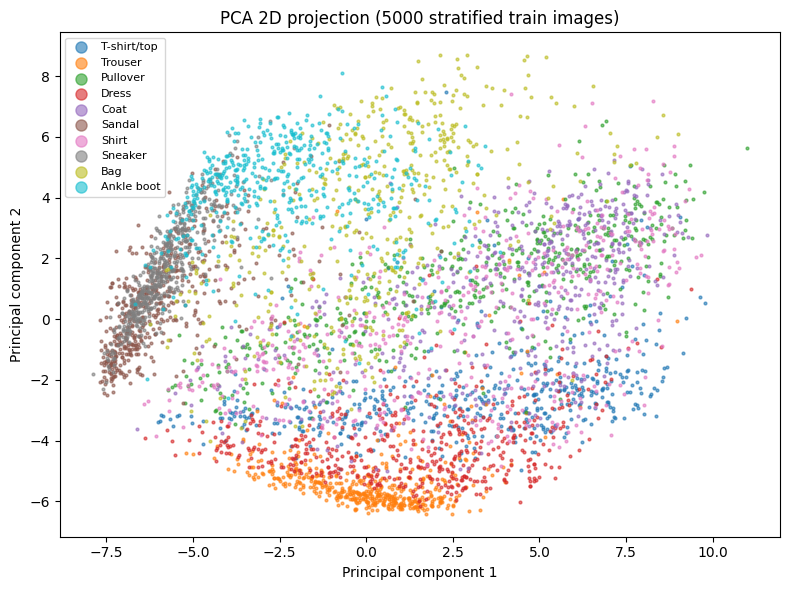

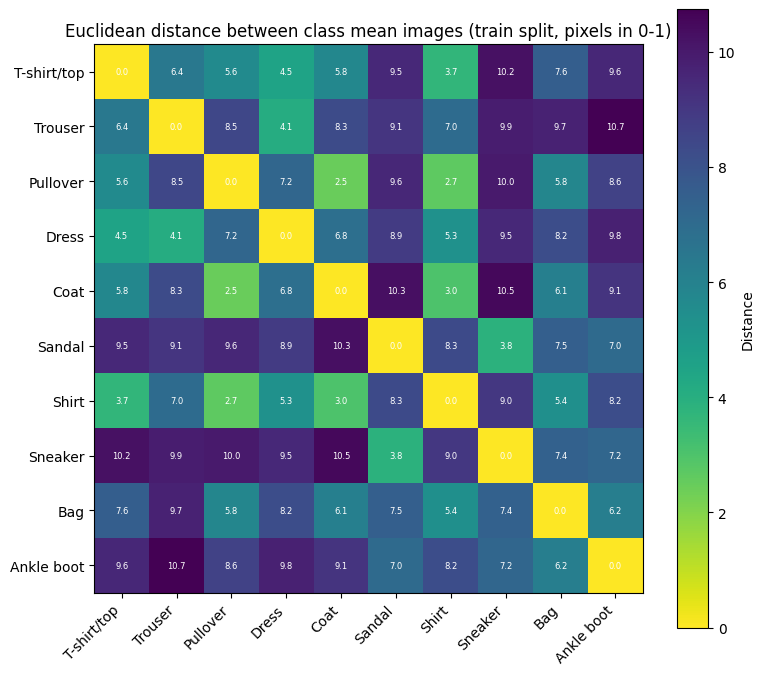

saved figures: ['eda_centroid_heatmap.png', 'eda_class_distribution.png', 'eda_confusable_panel.png', 'eda_mean_images.png', 'eda_pca_scatter.png', 'eda_pca_variance.png', 'eda_samples_per_class.png']


In [ ]:
# f) PCA (fit on the 54k train split only) and class-centroid distances
Z, evr = pca_projection(X_tr, 50)
dq["pca_evr_first2"] = [float(v) for v in evr[:2]]
print("PCA variance, PC1 and PC2:", dq["pca_evr_first2"], "| first 10:", float(evr[:10].sum()), "| 50:", float(evr.sum()))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, 51), np.cumsum(evr), marker="o", markersize=3)
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_title("PCA explained variance (fit on 54k train split)")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_pca_variance.png", dpi=150)
plt.show()

Zs, ys, _ = stratified_subset(Z, y_tr, 5000)  # 5000 points for readability, fixed seed
fig, ax = plt.subplots(figsize=(8, 6))
for c in range(10):
    ax.scatter(Zs[ys == c, 0], Zs[ys == c, 1], s=4, alpha=0.6, color=plt.cm.tab10(c), label=CLASS_NAMES[c])
ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.set_title("PCA 2D projection (5000 stratified train images)")
ax.legend(markerscale=4, fontsize=8, loc="best")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_pca_scatter.png", dpi=150)
plt.show()

D = class_centroid_distances(X_tr, y_tr)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(D.values, cmap="viridis_r")
ax.set_xticks(range(10))
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(10))
ax.set_yticklabels(CLASS_NAMES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{D.values[i, j]:.1f}", ha="center", va="center", fontsize=6, color="white")
ax.set_title("Euclidean distance between class mean images (train split, pixels in 0-1)")
fig.colorbar(im, ax=ax, label="Distance")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_centroid_heatmap.png", dpi=150)
plt.show()

dq_path.write_text(json.dumps(dq, indent=2))
print("saved figures:", sorted(p.name for p in FIGURES_DIR.glob("eda_*.png")))

## 3. Stratified split and audit (54,000 train / 6,000 validation, seed 42)

In [ ]:
splits = prepare_splits(X_train_full, y_train_full)
X_train, y_train, X_val, y_val = splits["X_train"], splits["y_train"], splits["X_val"], splits["y_val"]
assert len(X_train) == N_TRAIN and len(X_val) == N_VAL
assert not set(splits["idx_train"]) & set(splits["idx_val"]), "train/val index overlap"
assert np.array_equal(np.bincount(y_val, minlength=NUM_CLASSES), np.full(NUM_CLASSES, N_VAL // NUM_CLASSES)), "val not stratified"
print("train/val duplicate audit:", find_duplicates(X_train, X_val))
display(sanity_baselines(X_train, y_train, X_val, y_val))       # validation only; not part of the 9-model table
# PCA (fit on the train split only) is computed once, in section 2

train/val duplicate audit: {'n_within_a': 0, 'n_within_b': 0, 'n_overlap': 0, 'overlap_indices_a': [], 'examples_within_a': [], 'examples_within_b': []}


,name,val_accuracy,val_macro_f1
0,majority_class,0.100,0.018182
1,nearest_class_mean,0.692,0.688238


## 4. Features (pixels and HOG), cached; no held-out data

In [ ]:
assert HOG_DIM == hog_feature_dim(**HOG_PARAMS), "HOG_DIM in config does not match the HOG parameters"
feats = build_feature_sets(X_train, X_val)
for rep, dim in (("pixels", PIXEL_DIM), ("hog", HOG_DIM)):
    for part, n in (("train", N_TRAIN), ("val", N_VAL)):
        a = feats[rep][part]
        assert a.shape == (n, dim) and a.dtype == np.float32, (rep, part, a.shape, a.dtype)
        assert np.isfinite(a).all()
print({rep: {p: feats[rep][p].shape for p in feats[rep]} for rep in feats})
fig = plot_hog_example(X_train, 0); fig.savefig(FIGURES_DIR / "hog_example.png", dpi=150); plt.show()

{'pixels': {'train': (54000, 784), 'val': (6000, 784)}, 'hog': {'train': (54000, 6084), 'val': (6000, 6084)}}


## 5. Classical tuning (validation macro-F1; SVM on a stratified 10k subset)

In [ ]:
from src.classical_models import tune_classical, DEFAULT_GRIDS
from src.config import SVM_TUNE_N
import inspect

print("SVM tuning subset:", SVM_TUNE_N)
print("SVM parameter grid:", DEFAULT_GRIDS["svm"])
print("\nTuning implementation:\n")
print(inspect.getsource(tune_classical))

SVM tuning subset: 10000
SVM parameter grid: {'C': [1, 10]}

Tuning implementation:

def tune_classical(model_name, X_tr, y_tr, X_val, y_val, param_grid, subset_n=None, seed=SEED):
    """Manual grid loop (no CV). Select max val macro-F1; val accuracy breaks ties."""
    X_fit, y_fit = _subset(X_tr, y_tr, subset_n, seed)
    candidates = list(ParameterGrid(param_grid))  # ParameterGrid does not modify param_grid
    rows, scores = [], []
    for params in candidates:
        pipe = build_classical_pipeline(model_name, params)
        t0 = time.perf_counter()
        pipe.fit(X_fit, y_fit)
        fit_s = time.perf_counter() - t0
        pred = pipe.predict(X_val)
        acc = float(accuracy_score(y_val, pred))
        f1 = float(f1_score(y_val, pred, average="macro"))
        rows.append({"model": model_name, "params": str(params), "val_accuracy": acc,
                     "val_macro_f1": f1, "fit_seconds": fit_s, "n_train_used": len(y_fit)})
        scores.append((f1, acc))
        p

In [ ]:
from src.classical_models import build_classical_pipeline
import inspect

print(inspect.getsource(build_classical_pipeline))

def build_classical_pipeline(model_name, params=None):
    """Return a sklearn Pipeline. Steps: 'scaler' (logreg, svm only) and 'clf'."""
    params = dict(params or {})  # copy so the caller's dict is never mutated
    if model_name == "logreg":
        kw = dict(max_iter=500, random_state=42)
        kw.update(params)  # merge: caller may override defaults without duplicate-keyword error
        # multi_class is deprecated in recent sklearn; default is multinomial softmax, which we want
        return Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(**kw))])
    if model_name == "knn":
        kw = dict(algorithm="brute", n_jobs=-1)
        kw.update(params)
        return Pipeline([("clf", KNeighborsClassifier(**kw))])
    if model_name == "rf":
        kw = dict(n_estimators=200, n_jobs=-1, random_state=42)
        kw.update(params)
        return Pipeline([("clf", RandomForestClassifier(**kw))])
    if model_name == "svm":
        kw = dict(kernel="rbf", gamma="s

In [ ]:
best_params = run_classical_tuning(feats, y_train, y_val)
for k, v in best_params.items(): print(k, v)

In [ ]:
import ast
import time
import pandas as pd
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score
from src.classical_models import build_classical_pipeline, _subset
from src.config import SVM_TUNE_N, SEED

out = Path("results/tuning_svm_hog.csv")
out.parent.mkdir(parents=True, exist_ok=True)

X_fit, y_fit = _subset(
    feats["hog"]["train"], y_tr, SVM_TUNE_N, SEED
)
X_val = feats["hog"]["val"]

# Keep any previously completed SVM-HOG results.
rows = pd.read_csv(out).to_dict("records") if out.exists() else []
completed = {
    ast.literal_eval(row["params"])["C"]
    for row in rows
}

for C in [1, 10]:
    if C in completed:
        print(f"Skipping C={C}; already saved.")
        continue

    print(f"Starting SVM-HOG C={C} on {len(y_fit)} samples...", flush=True)
    model = build_classical_pipeline("svm", {"C": C})

    start = time.perf_counter()
    model.fit(X_fit, y_fit)
    fit_seconds = time.perf_counter() - start

    pred = model.predict(X_val)
    row = {
        "model": "svm",
        "params": str({"C": C}),
        "val_accuracy": float(accuracy_score(y_val, pred)),
        "val_macro_f1": float(f1_score(y_val, pred, average="macro")),
        "fit_seconds": fit_seconds,
        "n_train_used": len(y_fit),
    }
    rows.append(row)
    pd.DataFrame(rows).to_csv(out, index=False)

    print(
        f"Saved C={C} | accuracy={row['val_accuracy']:.4f} "
        f"| macro-F1={row['val_macro_f1']:.4f} "
        f"| fit={fit_seconds:.1f}s",
        flush=True,
    )

print("\nFinal SVM-HOG results:")
print(pd.DataFrame(rows).to_string(index=False))

Starting SVM-HOG C=1 on 10000 samples...
Saved C=1 | accuracy=0.8835 | macro-F1=0.8839 | fit=228.9s
Starting SVM-HOG C=10 on 10000 samples...
Saved C=10 | accuracy=0.8890 | macro-F1=0.8895 | fit=240.4s

Final SVM-HOG results:
model    params  val_accuracy  val_macro_f1  fit_seconds  n_train_used
  svm  {'C': 1}        0.8835      0.883919   228.888946         10000
  svm {'C': 10}        0.8890      0.889510   240.437181         10000


In [ ]:
import ast
import pandas as pd
from pathlib import Path
from src.classical_models import _select_best_index

results_dir = Path("results")
best_params = {}

for representation in ("pixels", "hog"):
    for model in ("logreg", "knn", "rf", "svm"):
        path = results_dir / f"tuning_{model}_{representation}.csv"

        if not path.exists():
            raise FileNotFoundError(f"Missing tuning results: {path}")

        df = pd.read_csv(path)

        if df.empty or df["val_macro_f1"].isna().any():
            raise ValueError(f"Invalid tuning results: {path}")

        scores = list(zip(df["val_macro_f1"], df["val_accuracy"]))
        best_idx = _select_best_index(scores)
        winner = df.iloc[best_idx]

        params = ast.literal_eval(winner["params"])
        best_params[(model, representation)] = params

        print(
            f"{model.upper():6} | {representation:6} | "
            f"params={params} | "
            f"accuracy={winner['val_accuracy']:.4f} | "
            f"macro-F1={winner['val_macro_f1']:.4f}"
        )

assert len(best_params) == 8, "Expected exactly eight model selections."
print("\nSUCCESS: all eight model selections reconstructed.")

LOGREG | pixels | params={'C': 0.1} | accuracy=0.8600 | macro-F1=0.8596
KNN    | pixels | params={'n_neighbors': 7} | accuracy=0.8635 | macro-F1=0.8633
RF     | pixels | params={'min_samples_leaf': 1} | accuracy=0.8882 | macro-F1=0.8871
SVM    | pixels | params={'C': 10} | accuracy=0.8777 | macro-F1=0.8773
LOGREG | hog    | params={'C': 0.1} | accuracy=0.8767 | macro-F1=0.8774
KNN    | hog    | params={'n_neighbors': 5} | accuracy=0.8748 | macro-F1=0.8724
RF     | hog    | params={'min_samples_leaf': 1} | accuracy=0.8698 | macro-F1=0.8687
SVM    | hog    | params={'C': 10} | accuracy=0.8890 | macro-F1=0.8895

SUCCESS: all eight model selections reconstructed.


In [ ]:
import json
from pathlib import Path

serializable = {
    f"{model}_{representation}": params
    for (model, representation), params in best_params.items()
}

Path("results/frozen_selection.json").write_text(
    json.dumps(serializable, indent=2)
)

print("Saved results/frozen_selection.json")

Saved results/frozen_selection.json


## 6. Classical final fits (54k train only; runtime gate; overfit check)

In [ ]:
models, fit_infos = run_classical_final_fits(feats, y_train, best_params)
rows = []
for (name, rep), pipe in models.items():
    oc = overfit_check(pipe, feats[rep]["train"], y_train, feats[rep]["val"], y_val)
    rows.append({"model": name, "rep": rep, **oc})
overfit_df = pd.DataFrame(rows); display(overfit_df.round(4))

[logreg] probe n=5000: 16.36s -> estimated fit on 54000: 176.7s (linear extrapolation)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


[logreg] n_train_used = 54000 of 54000 | fit_seconds = 131.5 | params = {'C': 0.1}
[logreg|pixels] estimate 177s (limit 1800s), gated = False, fit 131.5s
[logreg|pixels] n_train_used = 54000 of 54000
[knn] probe n=5000: 0.00s -> estimated fit on 54000: 0.0s (linear extrapolation)
[knn] estimated predict time on 6000 val images against 54000 stored rows: 22.2s
[knn] estimated predict time on 10000 test images against 54000 stored rows: 37.0s
[knn] n_train_used = 54000 of 54000 | fit_seconds = 0.0 | params = {'n_neighbors': 7}
[knn|pixels] estimate 0s (limit 1800s), gated = False, fit 0.0s
[knn|pixels] n_train_used = 54000 of 54000
[rf] probe n=5000: 9.61s -> estimated fit on 54000: 103.8s (linear extrapolation)
[rf] n_train_used = 54000 of 54000 | fit_seconds = 125.1 | params = {'min_samples_leaf': 1}
[rf|pixels] estimate 104s (limit 1800s), gated = False, fit 125.1s
[rf|pixels] n_train_used = 54000 of 54000
[svm] probe n=5000: 3.27s -> estimated fit on 54000: 380.9s (quadratic extrapol

,model,rep,train_acc,val_acc,gap,n_eval
0,logreg,pixels,0.8824,0.8600,0.0224,5000
1,knn,pixels,0.8850,0.8635,0.0215,5000
2,rf,pixels,1.0000,0.8882,0.1118,5000
3,svm,pixels,0.9802,0.9093,0.0709,5000
4,logreg,hog,1.0000,0.8767,0.1233,5000
5,knn,hog,0.9036,0.8748,0.0288,5000
6,rf,hog,1.0000,0.8698,0.1302,5000
7,svm,hog,1.0000,0.8937,0.1063,5000


In [ ]:
from pathlib import Path
import json
import pandas as pd

results = Path("results")

for name in [
    "fit_info.json",
    "frozen_selection.json",
    "tuning_svm_hog.csv",
]:
    path = results / name
    print(f"{name}: {'EXISTS' if path.exists() else 'MISSING'}")

fit_path = results / "fit_info.json"
if fit_path.exists():
    print("\n--- fit_info.json ---")
    print(fit_path.read_text())

print("\n--- SVM validation scores from tuning CSVs ---")
for name in ["tuning_svm_pixels.csv", "tuning_svm_hog.csv"]:
    path = results / name
    if path.exists():
        print(f"\n{name}")
        print(pd.read_csv(path).to_string(index=False))

fit_info.json: EXISTS
frozen_selection.json: EXISTS
tuning_svm_hog.csv: EXISTS

--- fit_info.json ---
[
  {
    "model": "logreg",
    "rep": "pixels",
    "params": {
      "C": 0.1
    },
    "fit_seconds": 131.484911001,
    "n_train_used": 54000,
    "n_train_available": 54000,
    "gated": false,
    "estimated_fit_seconds": 176.656958262001
  },
  {
    "model": "knn",
    "rep": "pixels",
    "params": {
      "n_neighbors": 7
    },
    "fit_seconds": 0.016636402000585804,
    "n_train_used": 54000,
    "n_train_available": 54000,
    "gated": false,
    "estimated_fit_seconds": 0.04297240079940821
  },
  {
    "model": "rf",
    "rep": "pixels",
    "params": {
      "min_samples_leaf": 1
    },
    "fit_seconds": 125.08697868199943,
    "n_train_used": 54000,
    "n_train_available": 54000,
    "gated": false,
    "estimated_fit_seconds": 103.76985367799317
  },
  {
    "model": "svm",
    "rep": "pixels",
    "params": {
      "C": 10
    },
    "fit_seconds": 267.6617486659

## 7. CNN training (train 54k / validation 6k only)
Train loss/accuracy are running averages in train mode (dropout on); validation is evaluated in eval mode after each epoch.
Early stopping on validation loss; the best-epoch weights are restored.

In [ ]:
import inspect
import src.data as data

print("Data module:", data.__file__)
print([name for name in dir(data) if "split" in name.lower() or "load" in name.lower()])

Data module: /content/fashion-tagging/src/data.py
['__loader__', 'load_dataset', 'load_test_dataset', 'load_training_dataset', 'prepare_splits', 'train_test_split']


In [ ]:
import inspect
from src.data import prepare_splits, load_training_dataset

print("=== prepare_splits ===")
print(inspect.signature(prepare_splits))
print(inspect.getsource(prepare_splits))

print("\n=== load_training_dataset ===")
print(inspect.signature(load_training_dataset))
print(inspect.getsource(load_training_dataset))

=== prepare_splits ===
(X_train_full, y_train_full, val_fraction=0.1, seed=42)
def prepare_splits(X_train_full, y_train_full, val_fraction=VAL_FRACTION, seed=SEED):
    """Stratified train/val split of the official TRAIN images only (test data never touched)."""
    n_total = len(y_train_full)
    n_val = int(round(n_total * val_fraction))
    idx_train, idx_val = train_test_split(
        np.arange(n_total), test_size=n_val, stratify=y_train_full, random_state=seed
    )
    idx_train, idx_val = np.sort(idx_train), np.sort(idx_val)  # sorted for readability; still deterministic
    out = {
        "X_train": X_train_full[idx_train], "y_train": y_train_full[idx_train],
        "X_val": X_train_full[idx_val], "y_val": y_train_full[idx_val],
        "idx_train": idx_train, "idx_val": idx_val,
    }
    # Write the audit file only for the official configuration, so tests with other seeds/mock data don't overwrite it
    if seed == SEED and val_fraction == VAL_FRACTION and n_total == N_TRA

In [ ]:
from src.data import load_training_dataset, prepare_splits
import numpy as np

# Load only the official 60,000 training images and labels
X_full, y_full = load_training_dataset()

# Recreate the project's exact seed-42 split
split = prepare_splits(X_full, y_full)

X_train_raw = split["X_train"]
y_train_raw = split["y_train"]
X_val_raw = split["X_val"]
y_val_raw = split["y_val"]

# Verify the split matches your existing labels
assert X_train_raw.shape == (54000, 28, 28)
assert X_val_raw.shape == (6000, 28, 28)
assert np.array_equal(y_train_raw, y_tr)
assert np.array_equal(y_val_raw, y_val)

# Restore the raw-image variables expected by the CNN cell
X_train = X_train_raw
X_val = X_val_raw

print("Restored raw images:")
print("X_train:", X_train.shape, X_train.dtype)
print("X_val:  ", X_val.shape, X_val.dtype)
print("Labels match the existing split.")

Restored raw images:
X_train: (54000, 28, 28) uint8
X_val:   (6000, 28, 28) uint8
Labels match the existing split.


In [ ]:
CNN_CFG = dict(lr=1e-3, batch_size=128, max_epochs=30, patience=5, dropout=0.5, seed=SEED)
cnn_mean, cnn_std = compute_mean_std(X_train)                    # train split only
X_tr_t = make_cnn_tensor(X_train, cnn_mean, cnn_std)
X_val_t = make_cnn_tensor(X_val, cnn_mean, cnn_std)
assert X_tr_t.shape == (N_TRAIN, 1, 28, 28) and X_tr_t.dtype == torch.float32
print("train-split mean/std: %.5f / %.5f | tensor mean/std: %.4f / %.4f" % (cnn_mean, cnn_std, X_tr_t.mean(), X_tr_t.std()))

set_global_seed(SEED)
_probe = build_cnn(CNN_CFG["dropout"])
print("output shape for randn(8,1,28,28):", tuple(_probe(torch.randn(8, 1, 28, 28)).shape), "| trainable params:", count_trainable_params(_probe))
assert count_trainable_params(_probe) == 241546

train-split mean/std: 0.28621 / 0.35316 | tensor mean/std: -0.0000 / 1.0000
output shape for randn(8,1,28,28): (8, 10) | trainable params: 241546


In [ ]:
# time ONE real epoch on this device before committing to the full run (throwaway model)
set_global_seed(SEED)
_, _, _one = train_cnn(build_cnn(CNN_CFG["dropout"]), X_tr_t, y_train, X_val_t, y_val, device,
                       lr=CNN_CFG["lr"], batch_size=CNN_CFG["batch_size"], max_epochs=1, patience=1, seed=SEED)
print("one epoch on %s: %.1f s -> worst case %d epochs ~ %.1f min" % (device, _one["train_seconds"], CNN_CFG["max_epochs"], _one["train_seconds"] * CNN_CFG["max_epochs"] / 60))

epoch   1 | train loss 0.6888 acc 0.7472 | val loss 0.3719 acc 0.8593 | 4.5s
one epoch on cuda: 4.5 s -> worst case 30 epochs ~ 2.3 min


epoch   1 | train loss 0.6888 acc 0.7472 | val loss 0.3719 acc 0.8593 | 1.7s
epoch   2 | train loss 0.4199 acc 0.8480 | val loss 0.2999 acc 0.8897 | 1.7s
epoch   3 | train loss 0.3623 acc 0.8684 | val loss 0.2688 acc 0.9017 | 1.7s
epoch   4 | train loss 0.3332 acc 0.8806 | val loss 0.2528 acc 0.9052 | 1.7s
epoch   5 | train loss 0.3073 acc 0.8887 | val loss 0.2437 acc 0.9127 | 1.7s
epoch   6 | train loss 0.2887 acc 0.8949 | val loss 0.2312 acc 0.9153 | 1.7s
epoch   7 | train loss 0.2779 acc 0.8985 | val loss 0.2145 acc 0.9205 | 1.7s
epoch   8 | train loss 0.2624 acc 0.9049 | val loss 0.2104 acc 0.9228 | 1.7s
epoch   9 | train loss 0.2538 acc 0.9085 | val loss 0.2163 acc 0.9207 | 1.7s
epoch  10 | train loss 0.2444 acc 0.9103 | val loss 0.2012 acc 0.9252 | 1.7s
epoch  11 | train loss 0.2326 acc 0.9158 | val loss 0.2000 acc 0.9265 | 1.7s
epoch  12 | train loss 0.2227 acc 0.9185 | val loss 0.1924 acc 0.9300 | 1.7s
epoch  13 | train loss 0.2183 acc 0.9216 | val loss 0.2075 acc 0.9192 | 1.7s

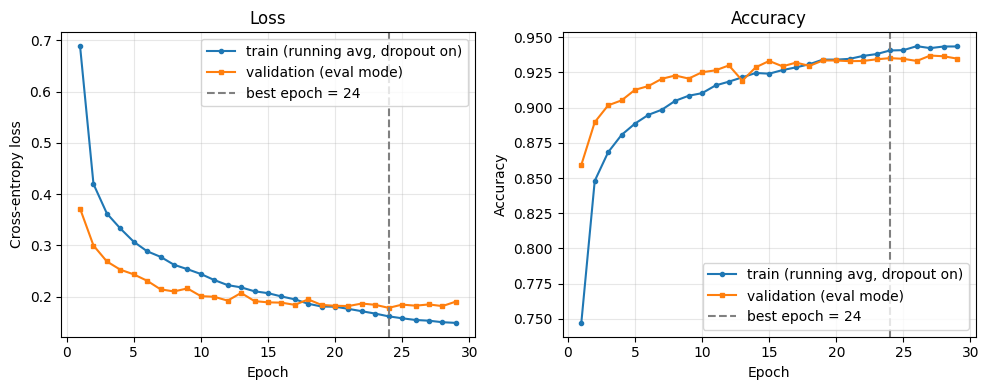

In [ ]:
set_global_seed(SEED)                                            # seed BEFORE building: reproducible initial weights
cnn_model = build_cnn(CNN_CFG["dropout"])
cnn_model, history, cnn_info = train_cnn(cnn_model, X_tr_t, y_train, X_val_t, y_val, device,
                                         lr=CNN_CFG["lr"], batch_size=CNN_CFG["batch_size"],
                                         max_epochs=CNN_CFG["max_epochs"], patience=CNN_CFG["patience"],
                                         seed=SEED, checkpoint_path=RESULTS_DIR / "cnn_best.pt")
print({k: v for k, v in cnn_info.items() if k != "epoch_seconds"})
fig = plot_learning_curves(history, cnn_info["best_epoch"]); fig.savefig(FIGURES_DIR / "cnn_learning_curves.png", dpi=150); plt.show()

In [ ]:
# overfit evidence: eval-mode accuracy on the full train split vs validation (restored best weights)
p_tr, _ = predict_cnn(cnn_model, X_tr_t, device); p_va, _ = predict_cnn(cnn_model, X_val_t, device)
cnn_train_eval = evaluate_predictions(y_train, p_tr, "cnn_train"); cnn_val_eval = evaluate_predictions(y_val, p_va, "cnn_val")
print("CNN train acc %.4f | val acc %.4f | gap %.4f" % (cnn_train_eval["accuracy"], cnn_val_eval["accuracy"], cnn_train_eval["accuracy"] - cnn_val_eval["accuracy"]))
assert abs(cnn_val_eval["accuracy"] - cnn_info["best_val_acc"]) < 1e-6, "restored weights do not reproduce best val acc"

CNN train acc 0.9680 | val acc 0.9352 | gap 0.0328


In [ ]:
from pathlib import Path
import json

required = [
    RESULTS_DIR / "frozen_selection.json",
    RESULTS_DIR / "fit_info.json",
    RESULTS_DIR / "cnn_best.pt",
    FIGURES_DIR / "cnn_learning_curves.png",
]

for path in required:
    print(f"{path}: {'OK' if path.is_file() else 'MISSING'}")

assert all(path.is_file() for path in required), (
    "A required artifact is missing. Stop and investigate."
)

flag = RESULTS_DIR / "test_gate_done.flag"
print("Test gate already executed:", flag.exists())

print("\nFrozen classical selection:")
print((RESULTS_DIR / "frozen_selection.json").read_text())

/content/fashion-tagging/results/frozen_selection.json: OK
/content/fashion-tagging/results/fit_info.json: OK
/content/fashion-tagging/results/cnn_best.pt: OK
/content/fashion-tagging/figures/cnn_learning_curves.png: OK
Test gate already executed: False

Frozen classical selection:
{
  "logreg_pixels": {
    "C": 0.1
  },
  "knn_pixels": {
    "n_neighbors": 7
  },
  "rf_pixels": {
    "min_samples_leaf": 1
  },
  "svm_pixels": {
    "C": 10
  },
  "logreg_hog": {
    "C": 0.1
  },
  "knn_hog": {
    "n_neighbors": 5
  },
  "rf_hog": {
    "min_samples_leaf": 1
  },
  "svm_hog": {
    "C": 10
  }
}


## 8. FREEZE, then the single final evaluation on the held-out images

In [ ]:
def _k(key): return "|".join(key) if isinstance(key, tuple) else str(key)
def _plain(o): return json.loads(json.dumps(o, default=lambda x: x.item() if hasattr(x, "item") else str(x)))

selected = {
    "classical_best_params": {_k(k): v for k, v in best_params.items()},
    "classical_fit_info": {_k(k): v for k, v in fit_infos.items()} if isinstance(fit_infos, dict) else fit_infos,
    "cnn": {**CNN_CFG, "best_epoch": cnn_info["best_epoch"], "best_val_loss": cnn_info["best_val_loss"],
            "best_val_acc": cnn_info["best_val_acc"], "train_mean": cnn_mean, "train_std": cnn_std,
            "trainable_params": count_trainable_params(cnn_model)},
    "hog_params": {k: list(v) if isinstance(v, tuple) else v for k, v in HOG_PARAMS.items()},
}
FROZEN_PATH = RESULTS_DIR / "selected_configs.json"
frozen_sha = freeze_selection(_plain(selected), FROZEN_PATH)
print("frozen:", FROZEN_PATH, "sha256:", frozen_sha)

frozen: /content/fashion-tagging/results/selected_configs.json sha256: f864a2ec5d44945af694462dcf7cb15cc08280f22124812465a8431e4fbc53bb


In [ ]:
from src.experiments import run_test_gate
# Section 8 only: load and validate the official held-out test split.
X_test, y_test = load_test_dataset()
print(verify_test_dataset(X_test, y_test))

def cnn_predict_fn(X_uint8):
    # Normalise with TRAIN mean/std, then predict in evaluation mode.
    return predict_cnn(cnn_model, make_cnn_tensor(X_uint8, cnn_mean, cnn_std), device)

gate = run_test_gate(FROZEN_PATH, models, X_test, y_test, cnn_predict_fn=cnn_predict_fn)
np.savez(RESULTS_DIR / "test_gate_outputs.npz", **{_k(k).replace("|", "__") + "__pred": v["y_pred"] for k, v in gate.items()})
print("models evaluated:", [_k(k) for k in gate])


{'test_shape': [10000, 28, 28], 'pixel_min': 0, 'pixel_max': 255, 'test_class_counts': [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]}
Test gate open: 10000 test images, freeze sha256 = f864a2ec5d44945af694462dcf7cb15cc08280f22124812465a8431e4fbc53bb
models evaluated: ['logreg|pixels', 'knn|pixels', 'rf|pixels', 'svm|pixels', 'logreg|hog', 'knn|hog', 'rf|hog', 'svm|hog', 'cnn']


## 9. Final evaluation of all 9 models (bootstrap CI, McNemar)

In [ ]:
from src.evaluation import mcnemar_test
evals, cis = {}, {}
for key, out in gate.items():
    evals[key] = evaluate_predictions(y_test, out["y_pred"], _k(key))
    cis[key] = {m: bootstrap_ci(y_test, out["y_pred"], metric=m, n_boot=1000, seed=SEED) for m in ("accuracy", "macro_f1")}
summary = pd.DataFrame([{"model": _k(k), "accuracy": e["accuracy"], "acc_lo": cis[k]["accuracy"][1], "acc_hi": cis[k]["accuracy"][2],
                         "macro_f1": e["macro_f1"], "f1_lo": cis[k]["macro_f1"][1], "f1_hi": cis[k]["macro_f1"][2]}
                        for k, e in evals.items()]).sort_values("macro_f1", ascending=False)
display(summary.round(4))
# CNN vs each classical model: McNemar (8 comparisons -> Bonferroni-adjusted p reported)
mc = []
for key in gate:
    if key == "cnn": continue
    r = mcnemar_test(y_test, gate["cnn"]["y_pred"], gate[key]["y_pred"])
    mc.append({"vs": _k(key), **r, "p_bonferroni": min(1.0, r["p_value"] * (len(gate) - 1))})
mcnemar_df = pd.DataFrame(mc); display(mcnemar_df)
summary.to_csv(RESULTS_DIR / "metrics_with_ci.csv", index=False)
mcnemar_df.to_csv(RESULTS_DIR / "mcnemar_cnn_vs_classical.csv", index=False)
pd.DataFrame({_k(k): e["per_class_recall"] for k, e in evals.items()}, index=CLASS_NAMES).T.to_csv(RESULTS_DIR / "per_class_recall.csv")
np.savez(RESULTS_DIR / "confusion_matrices.npz", **{_k(k).replace("|", "__"): e["confusion"] for k, e in evals.items()})

,model,accuracy,acc_lo,acc_hi,macro_f1,f1_lo,f1_hi
8,cnn,0.9274,0.9219,0.9327,0.9269,0.9214,0.9321
3,svm|pixels,0.8953,0.8887,0.9014,0.8951,0.8889,0.9008
7,svm|hog,0.8817,0.8753,0.8879,0.8816,0.8755,0.8877
2,rf|pixels,0.8756,0.8693,0.8818,0.8741,0.8682,0.8800
4,logreg|hog,0.8698,0.8632,0.8766,0.8702,0.8637,0.8764
5,knn|hog,0.8653,0.8583,0.8718,0.8621,0.8555,0.8682
6,rf|hog,0.8636,0.8571,0.8703,0.8618,0.8554,0.8682
1,knn|pixels,0.8500,0.8434,0.8567,0.8493,0.8430,0.8559
0,logreg|pixels,0.8411,0.8338,0.8482,0.8403,0.8336,0.8474


,vs,n01,n10,statistic,p_value,method,p_bonferroni
0,logreg|pixels,173,1036,614.593879,1.120926e-135,chi-square with continuity correction,8.967409e-135
1,knn|pixels,201,975,508.102891,1.640487e-112,chi-square with continuity correction,1.312389e-111
2,rf|pixels,187,705,299.651345,3.924024e-67,chi-square with continuity correction,3.139219e-66
3,svm|pixels,241,562,127.521793,1.428239e-29,chi-square with continuity correction,1.142591e-28
4,logreg|hog,258,834,302.770147,8.208406e-68,chi-square with continuity correction,6.566725e-67
5,knn|hog,237,858,351.050228,2.502871e-78,chi-square with continuity correction,2.002297e-77
6,rf|hog,208,846,384.980076,1.025035e-85,chi-square with continuity correction,8.200281e-85
7,svm|hog,220,677,231.812709,2.398985e-52,chi-square with continuity correction,1.919188e-51


In [ ]:
# diagnostic only (reports, alters nothing): exact duplicates between train and held-out images
print(find_duplicates(X_train_full, X_test))

{'n_within_a': 0, 'n_within_b': 0, 'n_overlap': 0, 'overlap_indices_a': [], 'examples_within_a': [], 'examples_within_b': []}


## 10. Inference benchmarks and parameter counts (same images, no shuffling)

In [ ]:
import inspect
from src.benchmarking import benchmark_classical_inference

print(inspect.getsource(benchmark_classical_inference))

def benchmark_classical_inference(pipeline, X_input, repeats=3, feature_fn=None) -> dict:
    """Time pipeline.predict on the whole of X_input (one call per repeat -> batch_size == n_images).

    feature_fn is None  -> X_input = PRECOMPUTED features: "predict only" (any scaler inside the pipeline IS included,
                           because it is part of pipeline.predict); includes_preprocessing=False.
    feature_fn given    -> X_input = RAW uint8 images: "end-to-end from raw images" = feature_fn(X) + predict;
                           includes_preprocessing=True.
    One untimed warm-up call on a small slice (<=256 rows) precedes timing. Unit: seconds / ms.
    """
    n = len(X_input)
    warm = X_input[:min(n, 256)]
    pipeline.predict(feature_fn(warm) if feature_fn is not None else warm)   # untimed warm-up
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        feats = feature_fn(X_input) if feature_fn is not None else X_input
        pipeline.p

In [ ]:
feat_fn = {"pixels": flatten_pixels, "hog": lambda X: extract_hog_features(X, **HOG_PARAMS)}
feats_ho = {rep: cached_features(X_test, rep, "test") for rep in feat_fn}      # read from cache; timing only, labels unused
bench = []
for (name, rep), pipe in models.items():
    for r in (benchmark_classical_inference(pipe, feats_ho[rep], repeats=3),
              benchmark_classical_inference(pipe, X_test, repeats=3, feature_fn=feat_fn[rep])):
        bench.append({"model": name, "rep": rep, **r})
X_ho_t = make_cnn_tensor(X_test, cnn_mean, cnn_std)                              # pre-normalised, outside the timed region
for dev in ["cpu"] + (["cuda"] if torch.cuda.is_available() else []):
    r = benchmark_cnn_inference(cnn_model, X_ho_t, torch.device(dev), batch_size=BENCH_BATCH_SIZE, warmup_batches=3, repeats=5)
    bench.append({"model": "cnn", "rep": "tensor", **r})
bench_df = pd.DataFrame(bench)
bench_df.to_json(RESULTS_DIR / "benchmarks.json", orient="records", indent=2)
display(bench_df.drop(columns=["repeats_s"]).round(4))

params = {"cnn": (count_trainable_params(cnn_model), "trainable parameters")}
for key, pipe in models.items(): params[_k(key)] = classical_param_count(pipe)
display(pd.DataFrame([{"model": k, "count": v[0], "note": v[1]} for k, v in params.items()]))

KeyboardInterrupt: 

In [ ]:

import json
import time
from pathlib import Path

feat_fn = {
    "pixels": flatten_pixels,
    "hog": lambda X: extract_hog_features(X, **HOG_PARAMS),
}

bench_path = RESULTS_DIR / "benchmarks.json"
bench = json.loads(bench_path.read_text()) if bench_path.exists() else []

def already_done(model, rep, label):
    return any(
        r.get("model") == model
        and r.get("rep") == rep
        and r.get("label") == label
        for r in bench
    )

def save_bench():
    bench_path.write_text(json.dumps(bench, indent=2))

# Use cached features for predict-only measurements.
feats_ho = {
    rep: cached_features(X_test, rep, "test")
    for rep in feat_fn
}

for (name, rep), pipe in models.items():
    for label, X_input, feature_fn in [
        ("predict only (precomputed features)", feats_ho[rep], None),
        ("end-to-end from raw images", X_test, feat_fn[rep]),
    ]:
        if already_done(name, rep, label):
            print(f"Skipping completed: {name}|{rep}|{label}")
            continue

        print(f"Benchmarking {name}|{rep}: {label}", flush=True)
        result = benchmark_classical_inference(
            pipe, X_input, repeats=1, feature_fn=feature_fn
        )
        row = {"model": name, "rep": rep, **result}
        bench.append(row)
        save_bench()
        print(f"Saved: {name}|{rep}|{label} -> {result}", flush=True)

# CNN benchmarks
X_ho_t = make_cnn_tensor(X_test, cnn_mean, cnn_std)

for dev in ["cpu"] + (["cuda"] if torch.cuda.is_available() else []):
    label = f"cnn_{dev}"
    if already_done("cnn", "tensor", label):
        continue

    print(f"Benchmarking CNN on {dev}", flush=True)
    result = benchmark_cnn_inference(
        cnn_model, X_ho_t, torch.device(dev),
        batch_size=BENCH_BATCH_SIZE, warmup_batches=1, repeats=1
    )
    bench.append({"model": "cnn", "rep": "tensor",
                  "label": label, **result})
    save_bench()
    print(f"Saved CNN {dev}: {result}", flush=True)

bench_df = pd.DataFrame(bench)
display(bench_df.round(4))

params = {"cnn": (count_trainable_params(cnn_model), "trainable parameters")}
for key, pipe in models.items():
    params[_k(key)] = classical_param_count(pipe)

display(pd.DataFrame([
    {"model": k, "count": v[0], "note": v[1]}
    for k, v in params.items()
]))


Benchmarking logreg|pixels: predict only (precomputed features)
Saved: logreg|pixels|predict only (precomputed features) -> {'device': 'cpu', 'batch_size': 10000, 'n_images': 10000, 'total_s_median': 0.08830278700042982, 'per_image_ms': 0.008830278700042982, 'repeats_s': [0.08830278700042982], 'includes_preprocessing': False, 'torch_threads': 1, 'os_cpu_count': 2, 'n_jobs': None, 'label': 'predict only (precomputed features)'}
Benchmarking logreg|pixels: end-to-end from raw images
Saved: logreg|pixels|end-to-end from raw images -> {'device': 'cpu', 'batch_size': 10000, 'n_images': 10000, 'total_s_median': 0.10632806300054654, 'per_image_ms': 0.010632806300054653, 'repeats_s': [0.10632806300054654], 'includes_preprocessing': True, 'torch_threads': 1, 'os_cpu_count': 2, 'n_jobs': None, 'label': 'end-to-end from raw images'}
Benchmarking knn|pixels: predict only (precomputed features)
Saved: knn|pixels|predict only (precomputed features) -> {'device': 'cpu', 'batch_size': 10000, 'n_images

,model,rep,device,batch_size,n_images,total_s_median,per_image_ms,repeats_s,includes_preprocessing,torch_threads,os_cpu_count,n_jobs,label,device_name
0,logreg,pixels,cpu,10000,10000,0.0883,0.0088,[0.08830278700042982],False,1,2,NaN,predict only (precomputed features),NaN
1,logreg,pixels,cpu,10000,10000,0.1063,0.0106,[0.10632806300054654],True,1,2,NaN,end-to-end from raw images,NaN
2,knn,pixels,cpu,10000,10000,22.5595,2.2560,[22.559515779999856],False,1,2,-1.0,predict only (precomputed features),NaN
3,knn,pixels,cpu,10000,10000,21.2067,2.1207,[21.206738906999817],True,1,2,-1.0,end-to-end from raw images,NaN
4,rf,pixels,cpu,10000,10000,0.5627,0.0563,[0.562749366999924],False,1,2,-1.0,predict only (precomputed features),NaN
5,rf,pixels,cpu,10000,10000,0.4899,0.0490,[0.48987450700042245],True,1,2,-1.0,end-to-end from raw images,NaN
6,svm,pixels,cpu,10000,10000,148.0429,14.8043,[148.04294920900065],False,1,2,NaN,predict only (precomputed features),NaN
7,svm,pixels,cpu,10000,10000,145.6006,14.5601,[145.6005727419997],True,1,2,NaN,end-to-end from raw images,NaN
8,logreg,hog,cpu,10000,10000,0.5676,0.0568,[0.5675510420005594],False,1,2,NaN,predict only (precomputed features),NaN
9,logreg,hog,cpu,10000,10000,33.0211,3.3021,[33.02105188200039],True,1,2,NaN,end-to-end from raw images,NaN


,model,count,note
0,cnn,241546.0,trainable parameters
1,logreg|pixels,7850.0,weights + intercepts
2,knn|pixels,NaN,non-parametric; stores N x d training values
3,rf|pixels,1812762.0,total tree nodes; not comparable to weights
4,svm|pixels,18996.0,support vectors; not comparable to weights
5,logreg|hog,60850.0,weights + intercepts
6,knn|hog,NaN,non-parametric; stores N x d training values
7,rf|hog,2250888.0,total tree nodes; not comparable to weights
8,svm|hog,7992.0,support vectors; not comparable to weights


## 11. Error analysis

,true_class,pred_class,count,rate_of_true_class
0,Shirt,T-shirt/top,99,0.099
1,T-shirt/top,Shirt,65,0.065
2,Shirt,Coat,62,0.062
3,Shirt,Pullover,60,0.060
4,Coat,Pullover,50,0.050
5,Pullover,Coat,33,0.033
6,Ankle boot,Sneaker,32,0.032
7,Coat,Shirt,32,0.032
8,Pullover,Shirt,30,0.030
9,Shirt,Dress,28,0.028


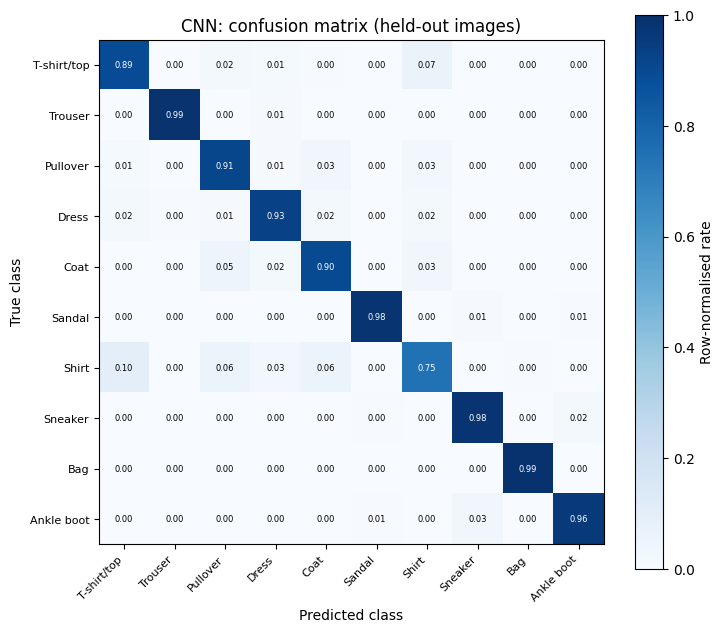

best classical by held-out macro-F1 (descriptive, post hoc): svm|pixels


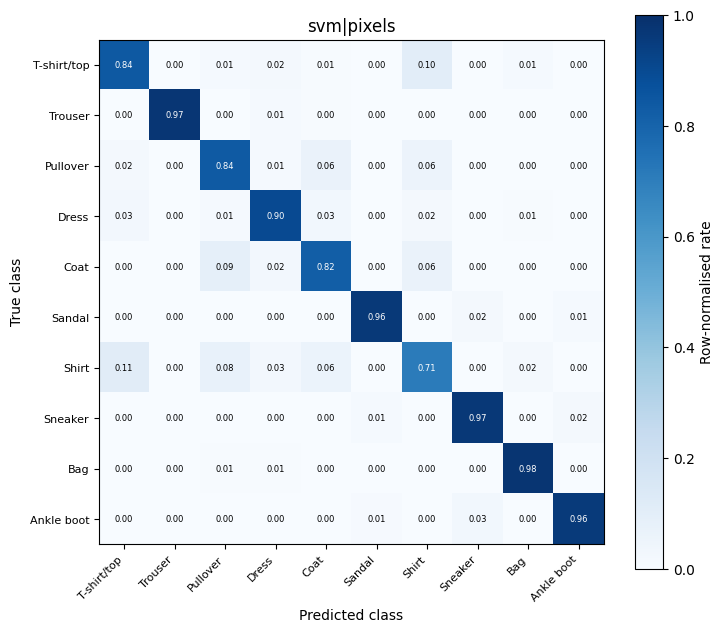

,model,n_errors,error_rate,n_unique_errors,n_shared_by_all
0,logreg|pixels,1589,0.1589,228,204
1,knn|pixels,1500,0.1500,169,204
2,rf|pixels,1244,0.1244,37,204
3,svm|pixels,1047,0.1047,45,204
4,logreg|hog,1302,0.1302,212,204
5,knn|hog,1347,0.1347,128,204
6,rf|hog,1364,0.1364,60,204
7,svm|hog,1183,0.1183,58,204
8,cnn,726,0.0726,18,204


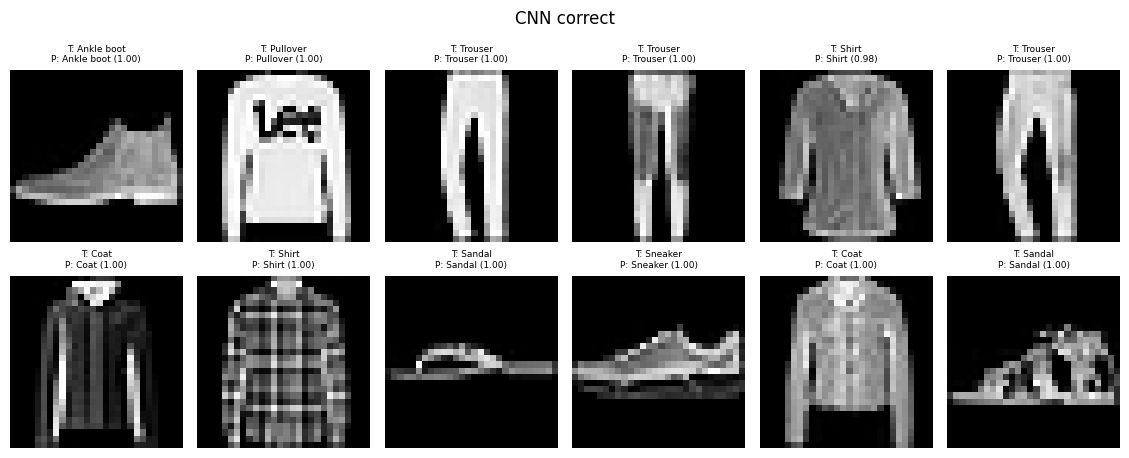

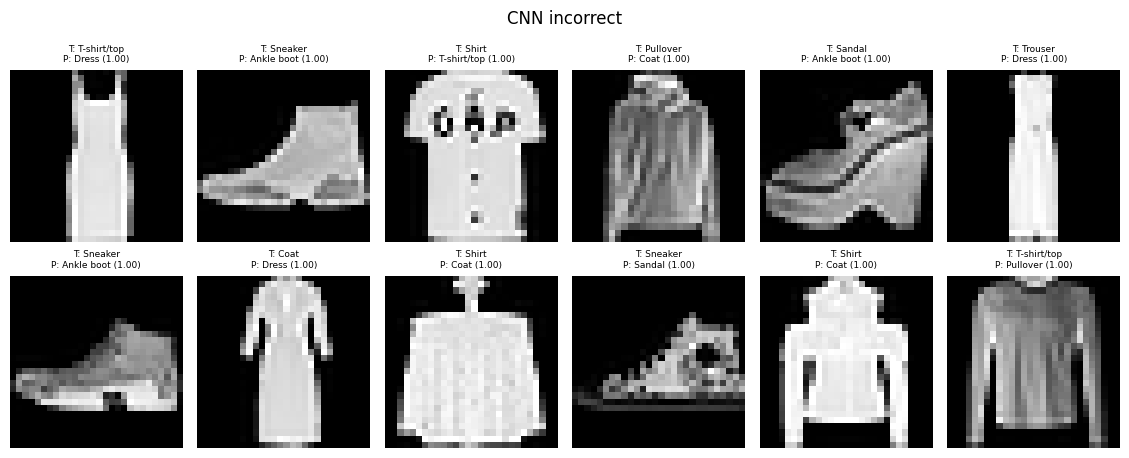

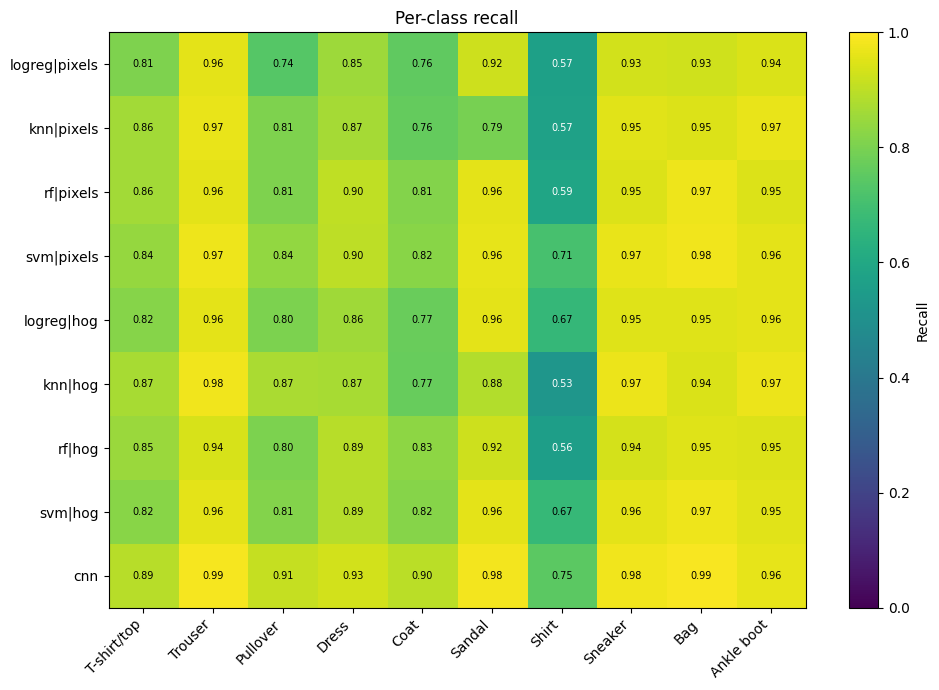

In [ ]:
cm_cnn = evals["cnn"]["confusion"]
display(top_confusions(cm_cnn, k=10).round(3))
fig = plot_confusion_matrix(cm_cnn, "CNN: confusion matrix (held-out images)"); fig.savefig(FIGURES_DIR / "cm_cnn.png", dpi=150); plt.show()
best_classical = max((k for k in gate if k != "cnn"), key=lambda k: evals[k]["macro_f1"])   # NOTE: chosen post hoc, descriptive only
print("best classical by held-out macro-F1 (descriptive, post hoc):", _k(best_classical))
fig = plot_confusion_matrix(evals[best_classical]["confusion"], _k(best_classical)); plt.show()
display(compare_errors(y_test, {_k(k): v["y_pred"] for k, v in gate.items()}))
for mode in ("correct", "incorrect"):
    fig = show_prediction_examples(X_test, y_test, gate["cnn"]["y_pred"], gate["cnn"]["conf"], mode=mode, n=12, title="CNN " + mode); plt.show()
fig = plot_per_class_recall_heatmap({_k(k): e for k, e in evals.items()}); fig.savefig(FIGURES_DIR / "per_class_recall.png", dpi=150); plt.show()

## 12. Results table, comparison, findings (all values computed)

,model,representation,training_config,n_train_used,accuracy,macro_f1,infer_cpu_predict_only_ms_per_img,infer_cpu_end_to_end_ms_per_img,infer_gpu_ms_per_img,params,params_note,fit_seconds,notes
0,Logistic regression,pixels,C=0.1,54000,0.8411,0.840317,0.00883,0.010633,n/a (CPU only),7850,weights + intercepts,131.484911,-
1,k-NN,pixels,n_neighbors=7,54000,0.85,0.849289,2.255952,2.120674,n/a (CPU only),n/a,non-parametric; stores N x d training values,0.016636,-
2,Random forest,pixels,min_samples_leaf=1,54000,0.8756,0.874135,0.056275,0.048987,n/a (CPU only),1812762,total tree nodes; not comparable to weights,125.086979,-
3,RBF-SVM,pixels,C=10,54000,0.8953,0.895054,14.804295,14.560057,n/a (CPU only),18996,support vectors; not comparable to weights,267.661749,hyperparameters tuned on a stratified subset o...
4,Logistic regression,HOG,C=0.1,54000,0.8698,0.870193,0.056755,3.302105,n/a (CPU only),60850,weights + intercepts,393.614126,-
5,k-NN,HOG,n_neighbors=5,54000,0.8653,0.862121,15.137228,18.48247,n/a (CPU only),n/a,non-parametric; stores N x d training values,0.116764,-
6,Random forest,HOG,min_samples_leaf=1,54000,0.8636,0.861801,0.082839,3.329037,n/a (CPU only),2250888,total tree nodes; not comparable to weights,348.484903,-
7,RBF-SVM,HOG,C=10,11770,0.8817,0.881589,48.426658,51.89992,n/a (CPU only),7992,support vectors; not comparable to weights,322.480322,hyperparameters tuned on a stratified subset o...
8,Small CNN,learned,"Adam lr=0.001, batch 128, dropout 0.5, best ep...",54000,0.9274,0.9269,0.440153,not measured (inputs are pre-normalised tensors),0.011625,241546,trainable parameters,49.014358,single seed 42; fit_seconds includes per-epoch...


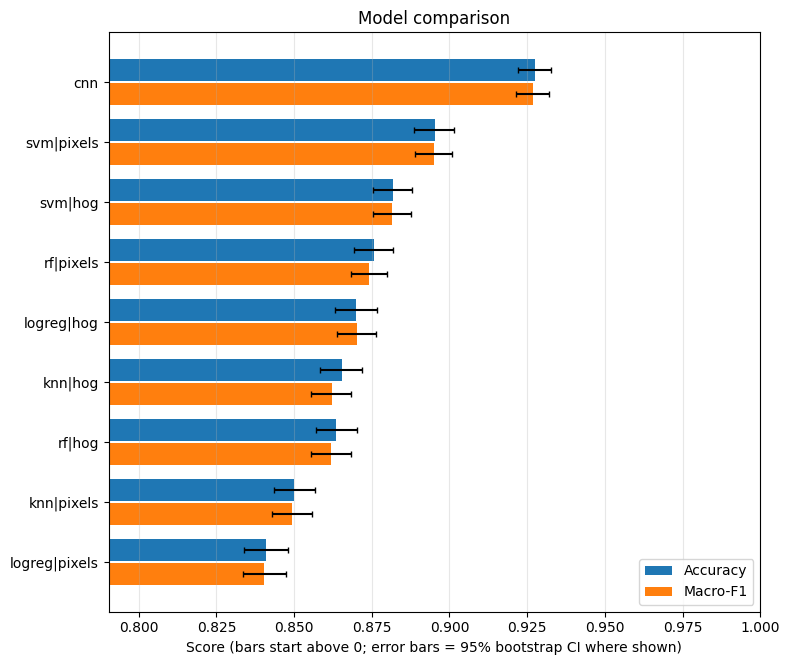

In [ ]:
NAME = {"logreg": "Logistic regression", "knn": "k-NN", "rf": "Random forest", "svm": "RBF-SVM", "cnn": "Small CNN"}
TEX_NAME = {**NAME, "knn": "$k$-NN"}
REP = {"pixels": "pixels", "hog": "HOG", "tensor": "learned"}

def _ms(model, rep, device, end_to_end):
    sel = bench_df[(bench_df.model == model) & (bench_df.rep == rep) & (bench_df.device == device)
                   & (bench_df.includes_preprocessing == end_to_end)]
    return float(sel.per_image_ms.iloc[0]) if len(sel) else None

entries = []
for key, e in evals.items():
    name, rep = key if isinstance(key, tuple) else ("cnn", "tensor")
    pcount, pnote = params[_k(key)]
    if name == "cnn":
        cfg = "Adam lr=%g, batch %d, dropout %g, best epoch %d (max %d, patience %d)" % (
            CNN_CFG["lr"], CNN_CFG["batch_size"], CNN_CFG["dropout"], cnn_info["best_epoch"], CNN_CFG["max_epochs"], CNN_CFG["patience"])
        n_used, fit_s = N_TRAIN, cnn_info["train_seconds"]
        notes = "single seed %d; fit_seconds includes per-epoch validation passes" % SEED
        po, e2e, gpu = _ms("cnn", "tensor", "cpu", False), "not measured (inputs are pre-normalised tensors)", _ms("cnn", "tensor", "cuda", False)
        gpu = gpu if gpu is not None else "no GPU available"
    else:
        fi = fit_infos[key]
        cfg = ", ".join("%s=%s" % kv for kv in fi["params"].items())
        n_used, fit_s = fi["n_train_used"], fi["fit_seconds"]
        notes = ("hyperparameters tuned on a stratified subset of %d of %d training images" % (min(SVM_TUNE_N, N_TRAIN), N_TRAIN)) if name == "svm" else ""
        if fi.get("gated"):
            notes = (notes + "; " if notes else "") + "final fit on a subset (runtime gate)"
        po, e2e, gpu = _ms(name, rep, "cpu", False), _ms(name, rep, "cpu", True), "n/a (CPU only)"
    entries.append(dict(model=NAME[name], representation=REP[rep], training_config=cfg, n_train_used=n_used,
                        accuracy=e["accuracy"], macro_f1=e["macro_f1"],
                        infer_cpu_predict_only_ms_per_img=po, infer_cpu_end_to_end_ms_per_img=e2e, infer_gpu_ms_per_img=gpu,
                        params=(pcount if pcount is not None else "n/a"), params_note=pnote, fit_seconds=fit_s, notes=(notes or "-")))
results_df = build_results_table(entries)                       # missing values -> "TBD"; unknown keys raise
save_results_table(results_df, RESULTS_DIR / "results_table.csv", RESULTS_DIR / "results_table.md")
display(results_df)
fig = plot_model_comparison(summary); fig.savefig(FIGURES_DIR / "model_comparison.png", dpi=150); plt.show()

In [ ]:
# LaTeX tables for the report, generated from the measured values (never retyped by hand)
def _f(x, nd=4): return "TBD" if x is None else ("%.*f" % (nd, x) if isinstance(x, (int, float)) else str(x))
rows = ["\\begin{table*}[t]", "\\centering",
        "\\caption{Test results for the nine models, measured once at the test gate (95\\% bootstrap confidence intervals, 1000 resamples).}",
        "\\label{tab:results}", "\\begin{tabular}{llcc}", "\\toprule", "Model & Representation & Accuracy [95\\% CI] & Macro-F1 [95\\% CI] \\\\", "\\midrule"]
for key in gate:
    name, rep = key if isinstance(key, tuple) else ("cnn", "tensor")
    a, alo, ahi = cis[key]["accuracy"]; f1, flo, fhi = cis[key]["macro_f1"]
    rows.append("%s & %s & %.4f [%.4f, %.4f] & %.4f [%.4f, %.4f] \\\\" % (TEX_NAME[name], REP[rep], a, alo, ahi, f1, flo, fhi))
rows += ["\\bottomrule", "\\end{tabular}", "\\end{table*}"]
(ROOT / "report").mkdir(exist_ok=True)
(ROOT / "report" / "results_table.tex").write_text("\n".join(rows) + "\n", encoding="utf-8")

hw = "%s; %d logical CPU cores" % ("GPU+CPU" if torch.cuda.is_available() else "CPU only", os.cpu_count())
rows = ["\\begin{table}[t]", "\\centering",
        "\\caption{Inference time per image on the 10{,}000 test images (%s; medians, model loading excluded) and parameter counts. ``Predict only'' uses precomputed features; ``end-to-end'' includes feature extraction from raw images. CNN inputs are pre-normalised tensors. Parameters: trainable weights for the CNN and logistic regression, total tree nodes for the random forest, support vectors for the SVM (not comparable to weights); $k$-NN is non-parametric.}" % hw,
        "\\label{tab:inference}", "\\footnotesize", "\\begin{tabular}{llrrr}", "\\toprule",
        "Model & Repr. & Predict only (ms) & End-to-end (ms) & Params \\\\", "\\midrule"]
for e in entries:
    nm = {v: k for k, v in NAME.items()}[e["model"]]
    p = e["params"]
    rows.append("%s & %s & %s & %s & %s \\\\" % (TEX_NAME[nm], e["representation"], _f(e["infer_cpu_predict_only_ms_per_img"], 3),
                _f(e["infer_cpu_end_to_end_ms_per_img"], 3) if not isinstance(e["infer_cpu_end_to_end_ms_per_img"], str) else "--",
                "n/a" if isinstance(p, str) else "{:,}".format(int(p)).replace(",", "{,}")))
rows += ["\\bottomrule", "\\end{tabular}", "\\end{table}"]
(ROOT / "report" / "inference_table.tex").write_text("\n".join(rows) + "\n", encoding="utf-8")
print("wrote report/results_table.tex and report/inference_table.tex")

wrote report/results_table.tex and report/inference_table.tex


In [ ]:
top = summary.iloc[0]
cnn_rank = list(summary.model).index("cnn") + 1
print("Measured: highest test macro-F1 = %s (%.4f). CNN rank by macro-F1: %d of %d (macro-F1 %.4f)." % (top.model, top.macro_f1, cnn_rank, len(summary), float(summary[summary.model == "cnn"].macro_f1.iloc[0])))
print("Interpret together with the CIs and McNemar table above; differences inside overlapping CIs are not evidence of a ranking.")

Measured: highest test macro-F1 = cnn (0.9269). CNN rank by macro-F1: 1 of 9 (macro-F1 0.9269).
Interpret together with the CIs and McNemar table above; differences inside overlapping CIs are not evidence of a ranking.


## 13. Limitations and reproducibility notes
* Single run (seed 42) for the headline CNN; run-to-run variance across seeds is **not** measured here (stretch experiment, reported separately if done).
* Models are trained on the 54k split only (no refit on train+val); any subsampling is printed in section 6 (`n_train_used`) and stored in `results/fit_info.json`.
* Fashion-MNIST is 28x28 grayscale studio-style images; conclusions do not transfer automatically to real inventory photos.
* Timings depend on the hardware recorded in section 0 / `results/benchmarks.json`; classical "predict only" includes the in-pipeline scaler; the GPU row exists only if a GPU was present.
* The held-out evaluation can run only once per `results/` folder (flag file); to re-run from scratch delete `results/test_gate_done.flag` deliberately and document why.
* Best-classical selection in section 11 is post hoc and descriptive only; model selection was frozen in section 8 before any held-out use.

In [ ]:
print(json.dumps(env, indent=2, default=str))
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests"], capture_output=True, text=True); print(r.stdout[-1500:])

{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "cpu": "x86_64 (2 logical cores)",
  "ram": "12.7 GB",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "sklearn": "1.6.1",
  "skimage": "0.25.2",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "cuda_available": true,
  "gpu_name": "Tesla T4",
  "torch_threads": 1,
  "seed": 42
}
.s...................................................................... [ 72%]
...........................                                              [100%]
98 passed, 1 skipped in 122.11s (0:02:02)



In [ ]:
from pathlib import Path
import json

required_files = [
    RESULTS_DIR / "test_gate_outputs.npz",
    RESULTS_DIR / "benchmarks.json",
    RESULTS_DIR / "fit_info.json",
    RESULTS_DIR / "frozen_selection.json",
    RESULTS_DIR / "cnn_best.pt",
    FIGURES_DIR / "cnn_learning_curves.png",
]

print("=== Required artifacts ===")
for path in required_files:
    print(f"{'OK      ' if path.is_file() else 'MISSING '} {path}")

print("\n=== Test gate ===")
flag = RESULTS_DIR / "test_gate_done.flag"
print("Completion flag:", flag.exists())

if flag.exists():
    print(flag.read_text())

print("\n=== Benchmark results ===")
bench_path = RESULTS_DIR / "benchmarks.json"
if bench_path.exists():
    bench = json.loads(bench_path.read_text())
    print("Benchmark records:", len(bench))
else:
    print("Benchmark results are missing.")

print("\n=== Git status ===")
!git status --short

=== Required artifacts ===
OK       /content/fashion-tagging/results/test_gate_outputs.npz
OK       /content/fashion-tagging/results/benchmarks.json
OK       /content/fashion-tagging/results/fit_info.json
OK       /content/fashion-tagging/results/frozen_selection.json
OK       /content/fashion-tagging/results/cnn_best.pt
OK       /content/fashion-tagging/figures/cnn_learning_curves.png

=== Test gate ===
Completion flag: True
{
  "created_utc": "2026-10-27T19:33:21+00:00",
  "freeze_sha256": "f864a2ec5d44945af694462dcf7cb15cc08280f22124812465a8431e4fbc53bb",
  "n_test": 10000
}

=== Benchmark results ===
Benchmark records: 18

=== Git status ===
 M figures/eda_centroid_heatmap.png
 M figures/eda_class_distribution.png
 M figures/eda_confusable_panel.png
 M figures/eda_mean_images.png
 M figures/eda_pca_scatter.png
 M figures/eda_pca_variance.png
 M figures/eda_samples_per_class.png
 M results/data_quality.json
?? figures/cm_cnn.png
?? figures/cnn_learning_curves.png
?? figures/hog_exam

In [ ]:
import pandas as pd
import json
from pathlib import Path

results_path = RESULTS_DIR / "results_table.csv"
if results_path.exists():
    display(pd.read_csv(results_path))
else:
    print("Missing results_table.csv")

print("\n=== Benchmark records by model ===")
bench = json.loads((RESULTS_DIR / "benchmarks.json").read_text())
display(pd.DataFrame(bench).groupby(["model", "rep"]).size().rename("records").reset_index())

print("\n=== Test gate outputs ===")
import numpy as np
with np.load(RESULTS_DIR / "test_gate_outputs.npz") as data:
    print("Saved prediction arrays:", len(data.files))
    print("Array names:", data.files)

,model,representation,training_config,n_train_used,accuracy,macro_f1,infer_cpu_predict_only_ms_per_img,infer_cpu_end_to_end_ms_per_img,infer_gpu_ms_per_img,params,params_note,fit_seconds,notes
0,Logistic regression,pixels,C=0.1,54000,0.8411,0.840317,0.008830,0.010632806300054653,n/a (CPU only),7850.0,weights + intercepts,131.484911,-
1,k-NN,pixels,n_neighbors=7,54000,0.8500,0.849289,2.255952,2.120673890699982,n/a (CPU only),NaN,non-parametric; stores N x d training values,0.016636,-
2,Random forest,pixels,min_samples_leaf=1,54000,0.8756,0.874135,0.056275,0.04898745070004225,n/a (CPU only),1812762.0,total tree nodes; not comparable to weights,125.086979,-
3,RBF-SVM,pixels,C=10,54000,0.8953,0.895054,14.804295,14.560057274199972,n/a (CPU only),18996.0,support vectors; not comparable to weights,267.661749,hyperparameters tuned on a stratified subset o...
4,Logistic regression,HOG,C=0.1,54000,0.8698,0.870193,0.056755,3.302105188200039,n/a (CPU only),60850.0,weights + intercepts,393.614126,-
5,k-NN,HOG,n_neighbors=5,54000,0.8653,0.862121,15.137228,18.48246964049995,n/a (CPU only),NaN,non-parametric; stores N x d training values,0.116764,-
6,Random forest,HOG,min_samples_leaf=1,54000,0.8636,0.861801,0.082839,3.329036891099895,n/a (CPU only),2250888.0,total tree nodes; not comparable to weights,348.484903,-
7,RBF-SVM,HOG,C=10,11770,0.8817,0.881589,48.426658,51.89992033680009,n/a (CPU only),7992.0,support vectors; not comparable to weights,322.480322,hyperparameters tuned on a stratified subset o...
8,Small CNN,learned,"Adam lr=0.001, batch 128, dropout 0.5, best ep...",54000,0.9274,0.926900,0.440153,not measured (inputs are pre-normalised tensors),0.011624715499965532,241546.0,trainable parameters,49.014358,single seed 42; fit_seconds includes per-epoch...



=== Benchmark records by model ===


,model,rep,records
0,cnn,tensor,2
1,knn,hog,2
2,knn,pixels,2
3,logreg,hog,2
4,logreg,pixels,2
5,rf,hog,2
6,rf,pixels,2
7,svm,hog,2
8,svm,pixels,2



=== Test gate outputs ===
Saved prediction arrays: 9
Array names: ['logreg__pixels__pred', 'knn__pixels__pred', 'rf__pixels__pred', 'svm__pixels__pred', 'logreg__hog__pred', 'knn__hog__pred', 'rf__hog__pred', 'svm__hog__pred', 'cnn__pred']


In [ ]:
import pandas as pd
import json

df = pd.read_csv(RESULTS_DIR / "results_table.csv")
print("Results table columns:")
print(df.columns.tolist())
display(df[[
    "model", "representation",
    "accuracy", "macro_f1",
    "infer_cpu_predict_only_ms_per_img",
    "infer_cpu_end_to_end_ms_per_img"
]])

bench = json.loads((RESULTS_DIR / "benchmarks.json").read_text())
print("\nRaw benchmark record example:")
print(json.dumps(bench[0], indent=2))

Results table columns:
['model', 'representation', 'training_config', 'n_train_used', 'accuracy', 'macro_f1', 'infer_cpu_predict_only_ms_per_img', 'infer_cpu_end_to_end_ms_per_img', 'infer_gpu_ms_per_img', 'params', 'params_note', 'fit_seconds', 'notes']


,model,representation,accuracy,macro_f1,infer_cpu_predict_only_ms_per_img,infer_cpu_end_to_end_ms_per_img
0,Logistic regression,pixels,0.8411,0.840317,0.008830,0.010632806300054653
1,k-NN,pixels,0.8500,0.849289,2.255952,2.120673890699982
2,Random forest,pixels,0.8756,0.874135,0.056275,0.04898745070004225
3,RBF-SVM,pixels,0.8953,0.895054,14.804295,14.560057274199972
4,Logistic regression,HOG,0.8698,0.870193,0.056755,3.302105188200039
5,k-NN,HOG,0.8653,0.862121,15.137228,18.48246964049995
6,Random forest,HOG,0.8636,0.861801,0.082839,3.329036891099895
7,RBF-SVM,HOG,0.8817,0.881589,48.426658,51.89992033680009
8,Small CNN,learned,0.9274,0.926900,0.440153,not measured (inputs are pre-normalised tensors)



Raw benchmark record example:
{
  "model": "logreg",
  "rep": "pixels",
  "device": "cpu",
  "batch_size": 10000,
  "n_images": 10000,
  "total_s_median": 0.08830278700042982,
  "per_image_ms": 0.008830278700042982,
  "repeats_s": [
    0.08830278700042982
  ],
  "includes_preprocessing": false,
  "torch_threads": 1,
  "os_cpu_count": 2,
  "n_jobs": null,
  "label": "predict only (precomputed features)"
}
